# 5. Exploratory Data Analysis with Visualization

**Goal:** see which features relate to a successful landing, then prepare the features for machine learning. Orange points (`Class` = 1) landed, and blue points (`Class` = 0) did not.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


## Flight number and payload mass

Later flights land more often, even with heavier payloads.

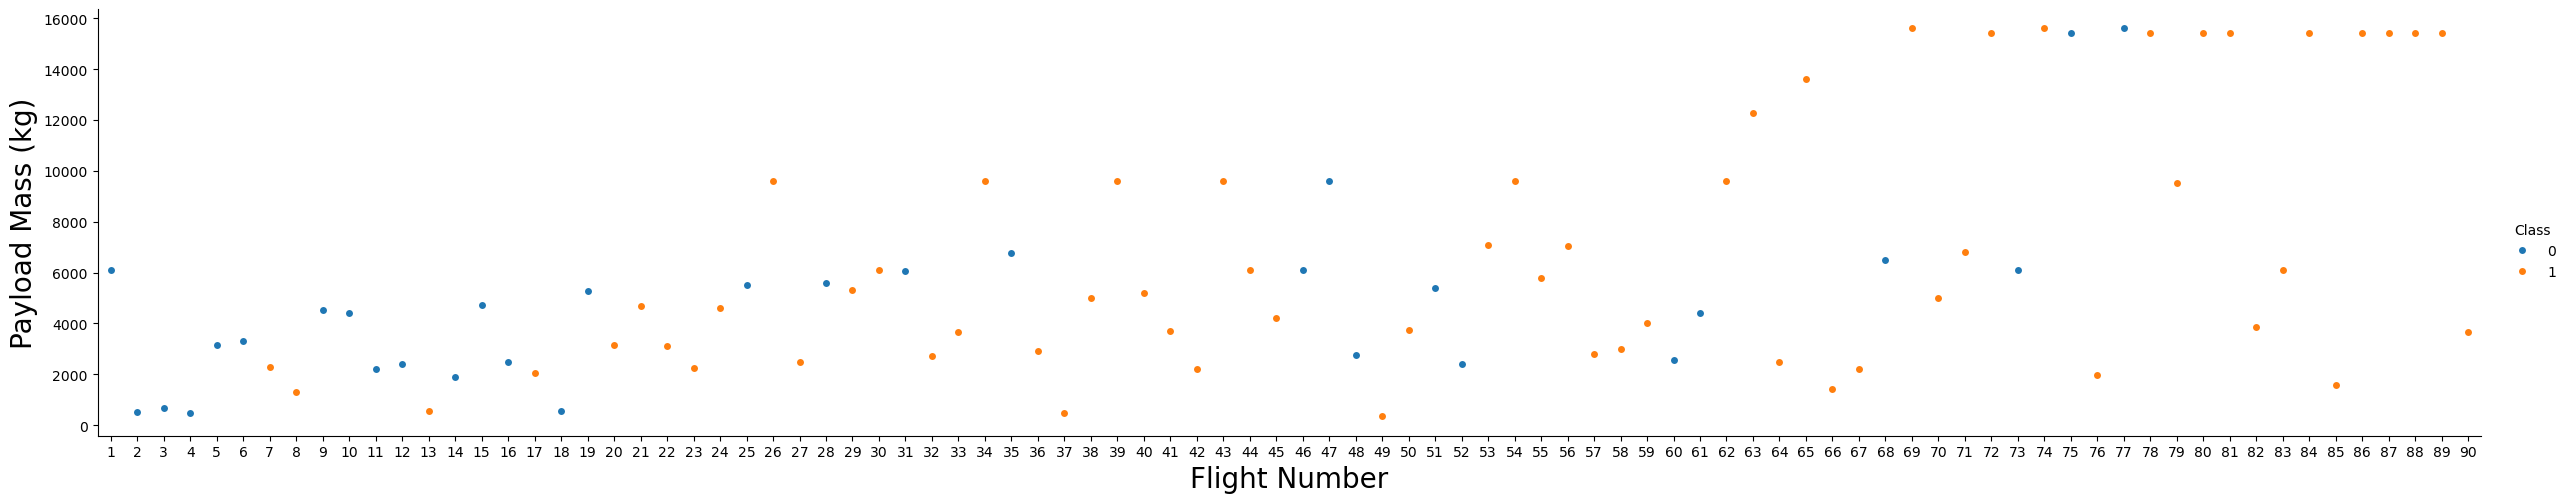

In [2]:
sns.catplot(y="PayloadMass", x="FlightNumber", hue="Class", data=df, aspect=5)
plt.xlabel("Flight Number", fontsize=20)
plt.ylabel("Payload Mass (kg)", fontsize=20)
plt.show()

## Flight number and launch site

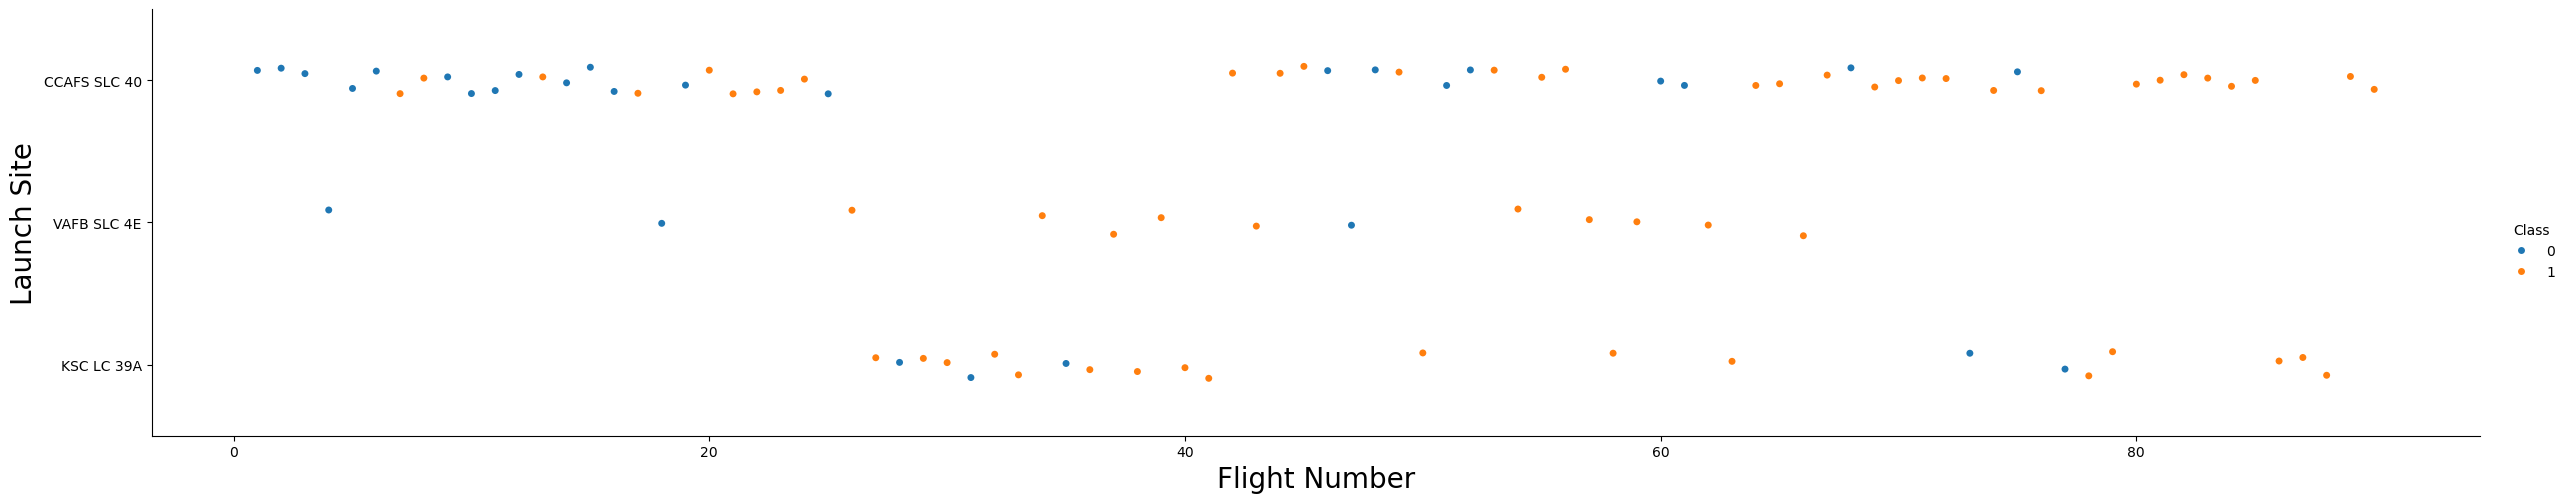

In [3]:
sns.catplot(y="LaunchSite", x="FlightNumber", hue="Class", data=df, aspect=5)
plt.xlabel("Flight Number", fontsize=20)
plt.ylabel("Launch Site", fontsize=20)
plt.show()

## Payload mass and launch site

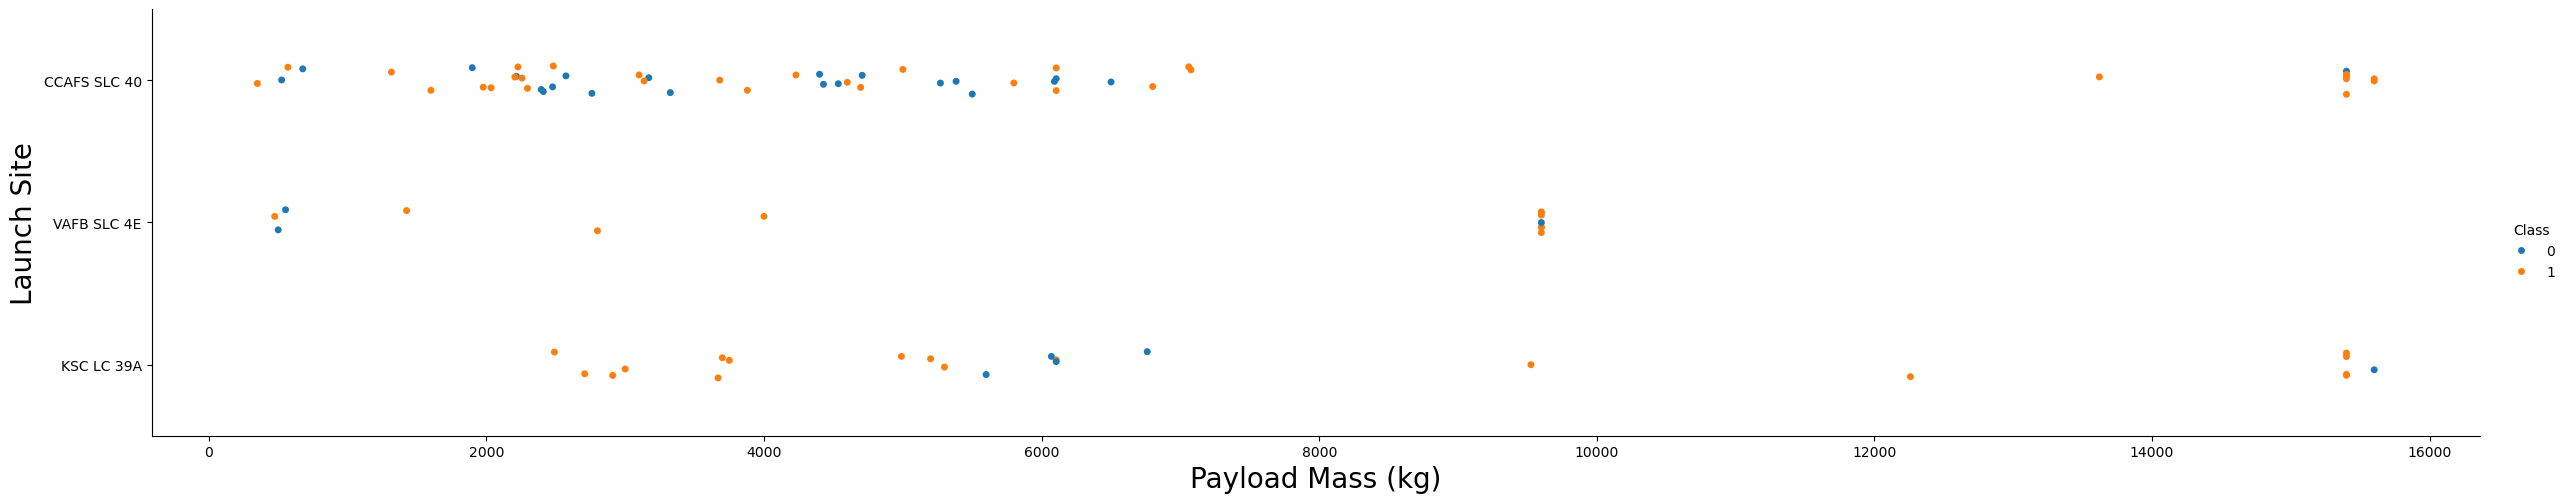

In [4]:
sns.catplot(y="LaunchSite", x="PayloadMass", hue="Class", data=df, aspect=5)
plt.xlabel("Payload Mass (kg)", fontsize=20)
plt.ylabel("Launch Site", fontsize=20)
plt.show()

## Success rate by orbit type

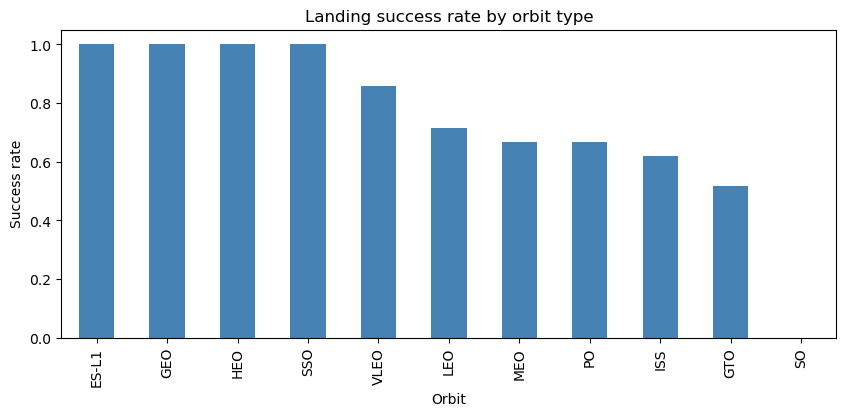

Orbit
ES-L1    1.00
GEO      1.00
HEO      1.00
SSO      1.00
VLEO     0.86
LEO      0.71
MEO      0.67
PO       0.67
ISS      0.62
GTO      0.52
SO       0.00
Name: Class, dtype: float64

In [5]:
orbit_rate = df.groupby("Orbit")["Class"].mean().sort_values(ascending=False)
orbit_rate.plot(kind="bar", figsize=(10, 4), color="steelblue")
plt.ylabel("Success rate")
plt.title("Landing success rate by orbit type")
plt.show()
orbit_rate.round(2)

## Flight number and orbit type

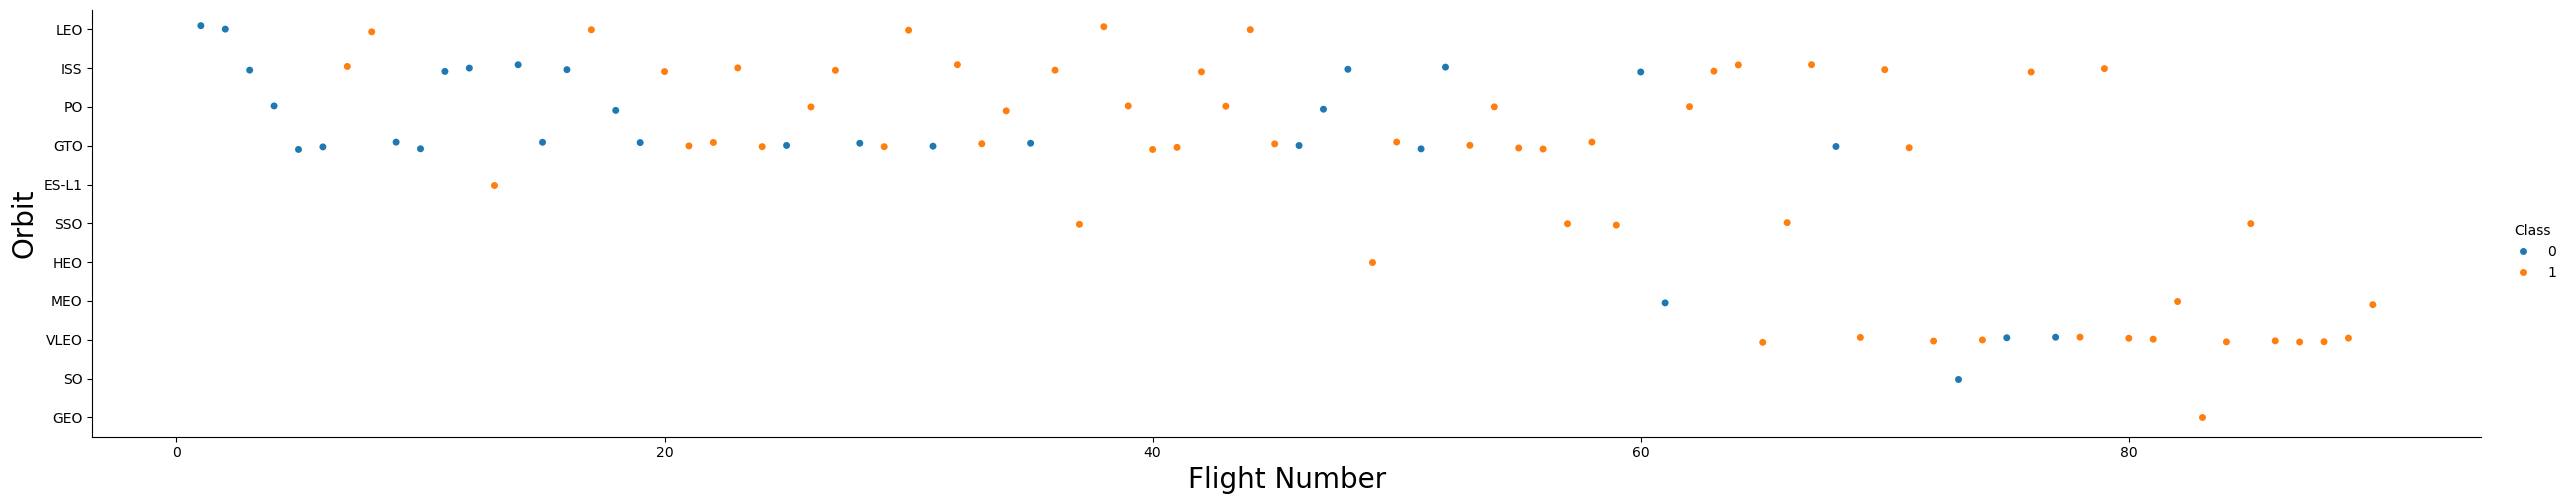

In [6]:
sns.catplot(y="Orbit", x="FlightNumber", hue="Class", data=df, aspect=5)
plt.xlabel("Flight Number", fontsize=20)
plt.ylabel("Orbit", fontsize=20)
plt.show()

## Payload mass and orbit type

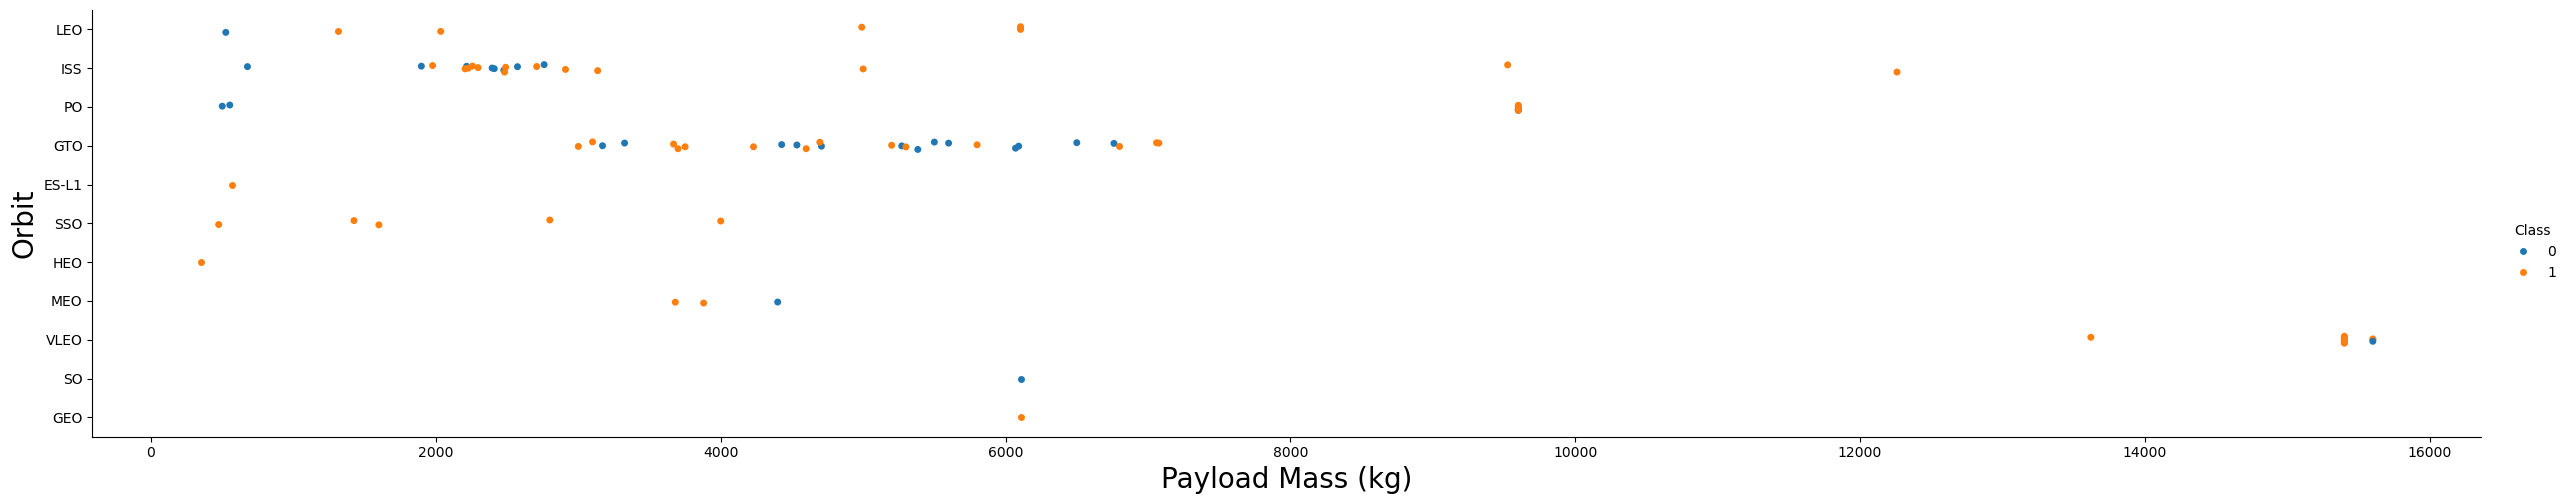

In [7]:
sns.catplot(y="Orbit", x="PayloadMass", hue="Class", data=df, aspect=5)
plt.xlabel("Payload Mass (kg)", fontsize=20)
plt.ylabel("Orbit", fontsize=20)
plt.show()

## Yearly success trend

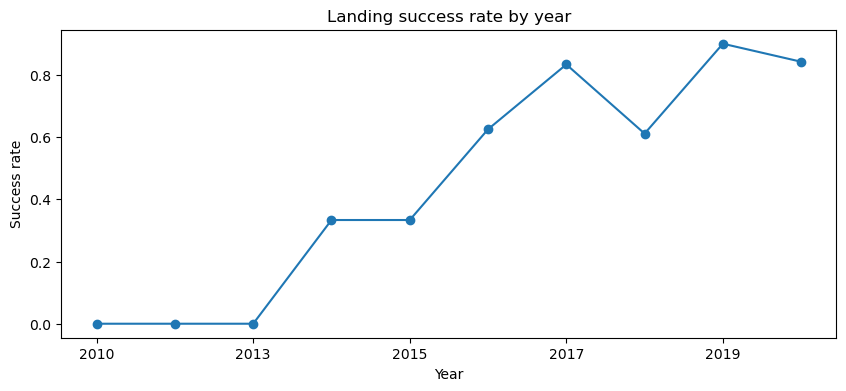

Year
2010    0.00
2012    0.00
2013    0.00
2014    0.33
2015    0.33
2016    0.62
2017    0.83
2018    0.61
2019    0.90
2020    0.84
Name: Class, dtype: float64

In [8]:
df["Year"] = df["Date"].str.split("-").str[0]
yearly = df.groupby("Year")["Class"].mean()
yearly.plot(kind="line", marker="o", figsize=(10, 4))
plt.ylabel("Success rate")
plt.title("Landing success rate by year")
plt.show()
yearly.round(2)

## Feature engineering

Convert the categorical features to one-hot (0/1) columns, and cast every column to `float64` for the models.

In [9]:
features = df[["FlightNumber", "PayloadMass", "Orbit", "LaunchSite", "Flights", "GridFins",
               "Reused", "Legs", "LandingPad", "Block", "ReusedCount", "Serial"]]
features_one_hot = pd.get_dummies(features, columns=["Orbit", "LaunchSite", "LandingPad", "Serial"])
features_one_hot = features_one_hot.astype("float64")
features_one_hot.to_csv("../data/dataset_part_3.csv", index=False)
features_one_hot.shape

(90, 80)